# 01a — Performance measures

Proposal 1 needs two performance measures (see the
[proposal](../proposals/01-training-load-vs-performance.md) and the
[data audit](00-data-audit.ipynb)):

- **Per-run efficiency factor (EF)**: dense — one value per run — but submaximal
  and noisy. The model's target.
- **Race VDOT**: sparse but maximal. Held out entirely, as an independent check.

This notebook builds both, and checks what drives EF before any load term is added.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from goalsplit_research import data, datasets

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (11, 3.2), "axes.spines.top": False, "axes.spines.right": False})

ds = data.fetch_dataset()
acts = data.activities_frame(ds)
runs = datasets.run_table(ds, acts)
races = datasets.road_races(ds, acts)
print(f"{len(runs)} runs between 20 min and 4 h with an efficiency factor")
print(f"{len(races)} road races (tagged, not hilly, ≤ 43 km, average HR ≥ 80% of max)")

192 runs between 20 min and 4 h with an efficiency factor
15 road races (tagged, not hilly, ≤ 43 km, average HR ≥ 80% of max)


## Race VDOT

Distance comes from the race title when it states one, else the nearest standard
distance (if GPS is within ±6%), else GPS. Time is an official time written in
brackets in the title, else moving time. Rows where distance was *not* read from
the title rest on an assumption, flagged below.

In [2]:
table = races.assign(
    km=(races["distance_m"] / 1000).round(2),
    time=pd.to_timedelta(races["time_s"], unit="s").astype(str).str[-8:],
    vdot=races["vdot"].round(1),
)
print(table[["localDate", "name", "km", "distance_source", "time", "time_source", "vdot"]].to_string(index=False))

assumed = table[table["distance_source"] != "name"]
print(f"\nDistance assumed (not in title) for {len(assumed)} races:", ", ".join(
    f"{d:%d %b %Y} {n}" for d, n in zip(assumed["localDate"], assumed["name"])))

 localDate                                        name    km  distance_source     time time_source  vdot
2024-02-17                                    Park Run  5.00             name 00:21:24 moving time  46.0
2024-03-02                                    Park Run  5.00             name 00:21:38 moving time  45.4
2024-05-05                                 Morning Run 21.10 nearest standard 01:40:34 moving time  44.8
2024-10-13 Pisa 10 - Forgot to stop my watch 🥲 (47:50) 10.00 nearest standard 00:47:50       title  42.1
2025-06-21                               Pisa walls 7k  7.00             name 00:33:39 moving time  40.9
2025-08-02                                 Wedding Run  5.00 nearest standard 00:21:30 moving time  45.8
2025-08-16                            Lucca Park Run 🏃  5.00             name 00:19:39 moving time  50.8
2025-10-12                                    Pisa 10k 10.00             name 00:39:34 moving time  52.6
2025-10-26                             Venice Marathon 

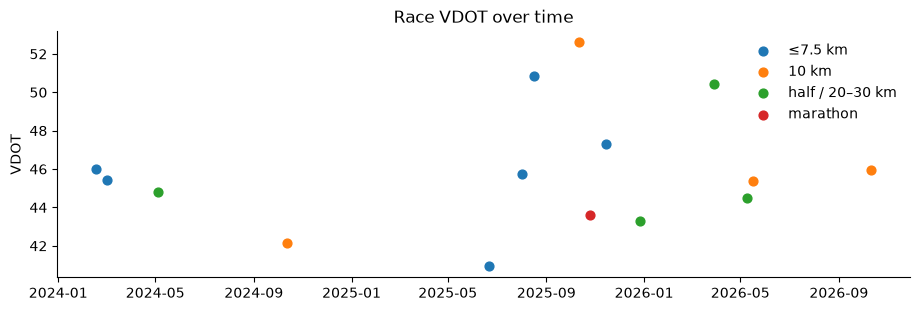

VDOT range 40.9–52.6, SD 3.2


In [3]:
fig, ax = plt.subplots()
for label, group in races.groupby(pd.cut(races["distance_m"], [0, 7500, 15000, 30000, 50000],
                                           labels=["≤7.5 km", "10 km", "half / 20–30 km", "marathon"]), observed=True):
    ax.scatter(group["localDate"], group["vdot"], label=label, s=40)
ax.set_title("Race VDOT over time")
ax.set_ylabel("VDOT")
ax.legend(frameon=False)
plt.show()
print(f"VDOT range {races['vdot'].min():.1f}–{races['vdot'].max():.1f}, SD {races['vdot'].std():.1f}")

## What drives per-run EF (before any load term)

If EF mostly reflects *how* a run was done (duration, terrain, intensity), those
must be controlled for, or the load model will be fitting run mix rather than
fitness. Heteroskedasticity- and autocorrelation-robust (HAC) standard errors,
because consecutive runs aren't independent.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1954      0.072     16.539      0.000       1.054       1.337
intensity     -0.0579      0.100     -0.579      0.562      -0.254       0.138
log_hours     -0.0787      0.013     -6.027      0.000      -0.104      -0.053
hilly         -0.1095      0.035     -3.146      0.002      -0.178      -0.041
R² = 0.263 · residual SD = 0.0760 · EF SD = 0.0879


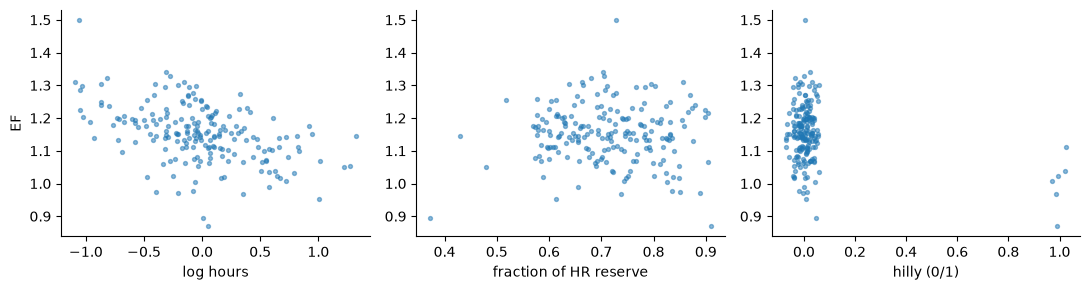

In [4]:
base = smf.ols("ef ~ intensity + log_hours + hilly", data=runs).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(base.summary().tables[1])
print(f"R² = {base.rsquared:.3f} · residual SD = {np.sqrt(base.scale):.4f} · EF SD = {runs['ef'].std():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, col, label in zip(axes, ["log_hours", "intensity", "hilly"], ["log hours", "fraction of HR reserve", "hilly (0/1)"]):
    jitter = np.random.default_rng(0).normal(0, 0.03, len(runs)) if col == "hilly" else 0
    ax.scatter(runs[col] + jitter, runs["ef"], s=8, alpha=0.5)
    ax.set_xlabel(label)
axes[0].set_ylabel("EF")
plt.tight_layout()
plt.show()

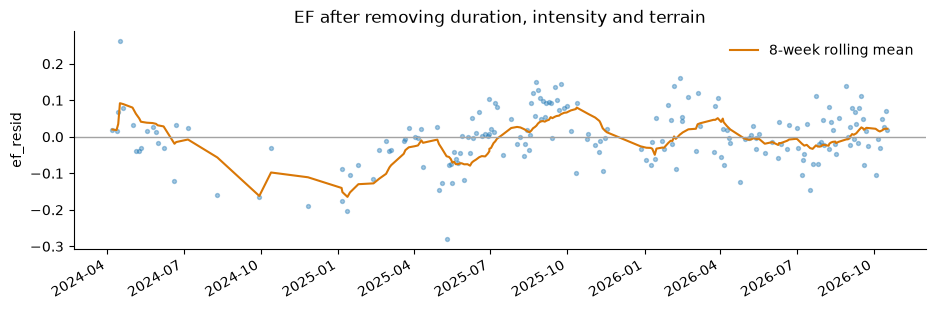

SD of the 8-week rolling mean (slow-moving signal): 0.0493
Residual SD per run (noise):                       0.0754


In [5]:
# Residual EF over time: what's left for training load to explain.
runs["ef_resid"] = base.resid
roll = runs.set_index("localDate")["ef_resid"].rolling("56D").mean()
ax = runs.plot.scatter(x="localDate", y="ef_resid", s=8, alpha=0.4)
roll.plot(ax=ax, color="#d97706", label="8-week rolling mean")
ax.axhline(0, color="#a3a3a3", lw=1)
ax.set_title("EF after removing duration, intensity and terrain")
ax.set_xlabel(""); ax.legend(frameon=False)
plt.show()
print(f"SD of the 8-week rolling mean (slow-moving signal): {roll.std():.4f}")
print(f"Residual SD per run (noise):                       {runs['ef_resid'].std():.4f}")

## Conclusions

**Race VDOT.** 15 road races qualify, VDOT 40.9–52.6 (SD 3.2). The best are Pisa 10k
(Oct 2025, 52.6), Lucca Parkrun (Aug 2025, 50.8) and the Firenze Half (Mar 2026, 50.4).
Five races' distances are assumed rather than read from the title (two "Morning Run"
half-distance races, Pisa 10 2024, the Wedding Run and Wing for Life), so naming races
with their distance would remove that assumption.

**What drives per-run EF.** Duration dominates: efficiency drops about 0.08 per
log-hour. Hilly runs are about 0.11 less efficient *even after grade adjustment*,
which suggests Minetti GAP under-credits trail and technical terrain. Intensity has
no detectable effect once duration is controlled for. The three covariates explain
26% of EF variance.

**Enough signal remains for a load model.** After removing those effects, the slow
8-week trend has an SD of 0.049 against per-run noise of 0.075. Run-level modelling
can see a trend that weekly medians drowned in noise.